In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, os
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
OUT = os.path.join(ROOT, 'results', '02_pareto')
os.makedirs(OUT, exist_ok=True)

# 02 - Rebuilding the Pareto front with many weightings

**Motivation.** The starting prototype ran QAOA for *one* weighting of the three goals (cost, peak load, battery wear) = (0.5, 0.3, 0.2), so it only ever found one compromise schedule. EV depot operators want the whole *trade-off menu* - the **Pareto front**: schedules where no goal can be improved without worsening another.

**Workflow**
1. Brute force all 216 feasible schedules of the 3 vehicle x 4 slot example (12 qubits) and compute the true front.
2. Sweep a grid of weightings on the simplex (w_cost + w_peak + w_wear = 1, step 1/8 -> 45 weightings).
3. For each weighting: build the QUBO, run depth p=2 QAOA (XY mixer, Dicke start), optimise with COBYLA on the exact statevector, then draw 256 measurement shots.
4. Union all sampled schedules, take their non-dominated subset and compare to the true front.
5. Baselines with the *same total number of shots*: uniform random over feasible schedules, and uniform over all 4096 bitstrings (infeasible shots are wasted).

Metrics: true front points recovered, and 3D hypervolume (volume dominated up to a reference point slightly worse than every objective maximum; larger is better).

In [3]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
from evqaoa import EXAMPLE_3x4 as INST, all_feasible, objectives, objective_scales, pareto_front
from experiments.pareto import (weight_grid, run_weighting, front_recovery, hypervolume,
                                random_baseline, cumulative_curves)

SHOTS_PER_WEIGHTING, DENOM, P = 256, 8, 2
NAMES = ['cost', 'peak', 'wear']
table = [objectives(INST, x) for x in all_feasible(INST)]
true_front = pareto_front(table)
scale = objective_scales(INST)
ref = tuple(float(v) + 1 for v in np.max(table, axis=0))   # slightly worse than every maximum
hv_true = hypervolume(true_front, ref)
print('feasible schedules:', len(table), '| true front:', true_front)
print('reference point:', ref, '| hypervolume of true front:', hv_true)

feasible schedules: 216 | true front: [(6, 18, 6), (8, 14, 5), (10, 12, 6), (10, 14, 4), (11, 10, 4), (12, 18, 3), (13, 10, 3)]
reference point: (22.0, 19.0, 10.0) | hypervolume of true front: 772.0


## 1. QAOA sweep over weightings
Two variants: **independent** (each weighting starts from a random angle guess) and **warm-started** (each weighting starts from the previous weighting's optimal angles - *parameter reuse*, which should need fewer restarts).

In [4]:
grid = weight_grid(DENOM)
print(len(grid), 'weightings')
t0 = time.time()
cold = [run_weighting(INST, w, scale, p=P, shots=SHOTS_PER_WEIGHTING, seed=i, restarts=1)
        for i, w in enumerate(grid)]
t_cold = time.time() - t0
t0 = time.time()
warm, prev = [], None
for i, w in enumerate(grid):
    r = run_weighting(INST, w, scale, p=P, x_init=prev, shots=SHOTS_PER_WEIGHTING, seed=1000 + i, restarts=1)
    prev = r['theta']; warm.append(r)
t_warm = time.time() - t0
print(f'independent sweep {t_cold:.0f}s, warm-start sweep {t_warm:.0f}s')

45 weightings


independent sweep 228s, warm-start sweep 337s


## 2. Sampled schedules and the baselines (same total shot budget)

In [5]:
def flatten(runs):
    return [s for r in runs for s in r['samples']]

seq = {'QAOA (independent)': flatten(cold), 'QAOA (warm-start)': flatten(warm)}
budget = len(seq['QAOA (independent)'])
RANDOM_SEEDS = range(20)
rand_feas = [random_baseline(INST, budget, seed=s, feasible_only=True) for s in RANDOM_SEEDS]
rand_all = [random_baseline(INST, budget, seed=s, feasible_only=False) for s in RANDOM_SEEDS]
checkpoints = sorted(set(list(range(64, budget + 1, 64)) + [256, 512, 1024, budget]))
curves = {k: cumulative_curves(v, true_front, ref, checkpoints) for k, v in seq.items()}
def mean_curve(runs):
    cs = [cumulative_curves(r, true_front, ref, checkpoints) for r in runs]
    return [np.mean([c[i] for c in cs], axis=0) for i in (0, 1)], [[c[i] for c in cs] for i in (0, 1)]
(rf_rec, rf_hv), rf_raw = mean_curve(rand_feas)
(ra_rec, ra_hv), ra_raw = mean_curve(rand_all)
curves['Random feasible (mean of 20 seeds)'] = (rf_rec, rf_hv)
curves['Random all 4096 bitstrings (mean of 20 seeds)'] = (ra_rec, ra_hv)

feas_frac = {k: float(np.mean([s is not None for s in v])) for k, v in seq.items()}
feas_frac['random all bitstrings'] = float(np.mean([s is not None for r in rand_all for s in r]))
summary = {k: dict(front_found=int(v[0][-1]), hypervolume=float(v[1][-1]), hv_fraction=float(v[1][-1] / hv_true))
           for k, v in curves.items()}
for k, v in summary.items():
    print(f'{k:50s} front {v["front_found"]:.1f}/7  HV {v["hypervolume"]:.1f} ({100*v["hv_fraction"]:.1f}% of true)')
print('fraction of shots that are feasible:', feas_frac)

QAOA (independent)                                 front 7.0/7  HV 772.0 (100.0% of true)
QAOA (warm-start)                                  front 7.0/7  HV 772.0 (100.0% of true)
Random feasible (mean of 20 seeds)                 front 7.0/7  HV 772.0 (100.0% of true)
Random all 4096 bitstrings (mean of 20 seeds)      front 6.0/7  HV 771.6 (99.9% of true)
fraction of shots that are feasible: {'QAOA (independent)': 1.0, 'QAOA (warm-start)': 1.0, 'random all bitstrings': 0.05291232638888889}


## 3. Plot: 2D projections of the objective space
Grey = all 216 feasible schedules, red = true Pareto front, blue ring = schedules QAOA sampled that are on the true front, blue dots = other schedules QAOA sampled.

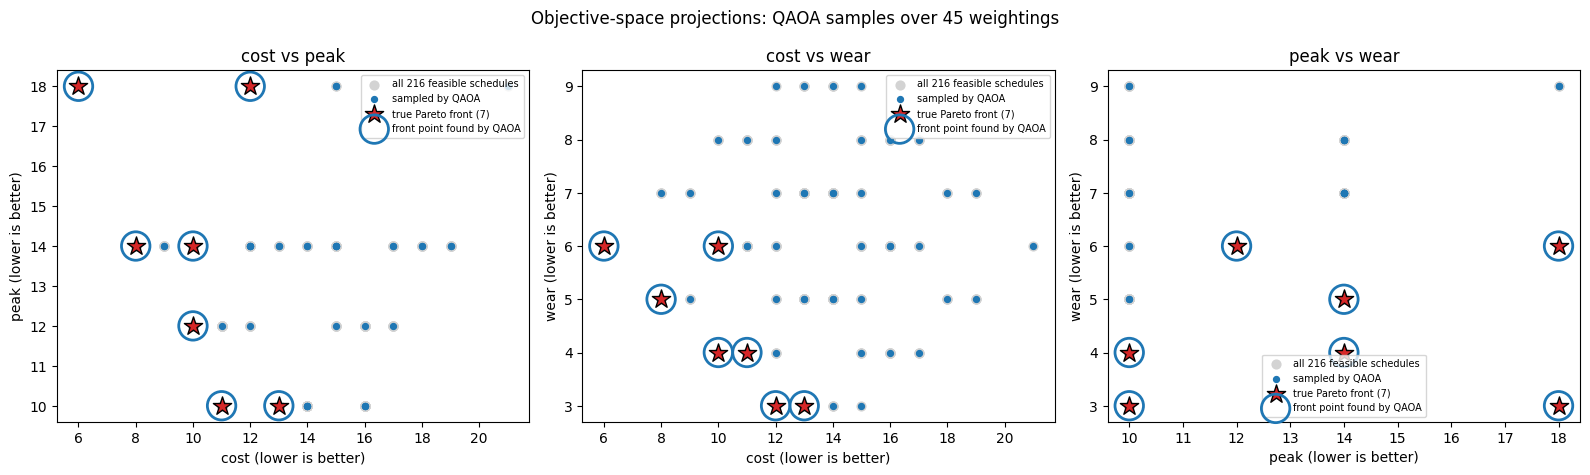

In [6]:
qaoa_pts = sorted({s for s in seq['QAOA (independent)'] + seq['QAOA (warm-start)'] if s})
qaoa_front = [p for p in qaoa_pts if p in set(true_front)]
pairs = [(0, 1), (0, 2), (1, 2)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (a, b) in zip(axes, pairs):
    ax.scatter([t[a] for t in table], [t[b] for t in table], c='lightgrey', s=40, label='all 216 feasible schedules')
    ax.scatter([t[a] for t in qaoa_pts], [t[b] for t in qaoa_pts], c='tab:blue', s=18, label='sampled by QAOA')
    ax.scatter([t[a] for t in true_front], [t[b] for t in true_front], c='tab:red', marker='*', s=190,
               edgecolors='k', label='true Pareto front (7)')
    ax.scatter([t[a] for t in qaoa_front], [t[b] for t in qaoa_front], facecolors='none', edgecolors='tab:blue',
               s=420, linewidths=2, label='front point found by QAOA')
    ax.set_xlabel(NAMES[a] + ' (lower is better)'); ax.set_ylabel(NAMES[b] + ' (lower is better)')
    ax.set_title(f'{NAMES[a]} vs {NAMES[b]}'); ax.legend(fontsize=7)
fig.suptitle('Objective-space projections: QAOA samples over 45 weightings')
fig.tight_layout(); fig.savefig(f'{OUT}/projections.png', dpi=140); plt.show()

## 4. Plot: front points recovered vs cumulative shots

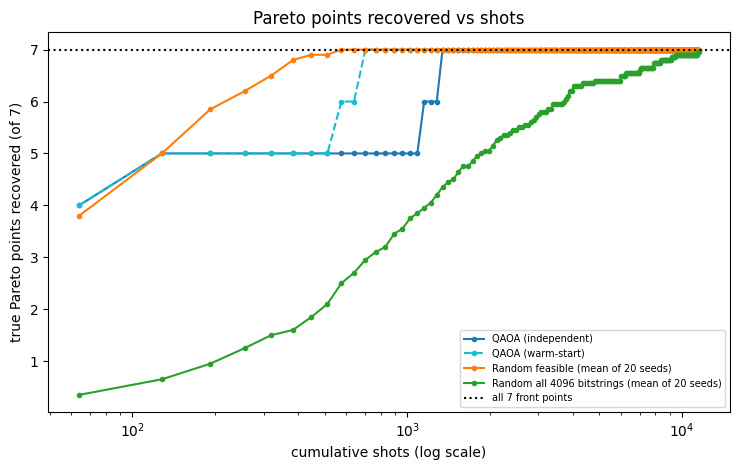

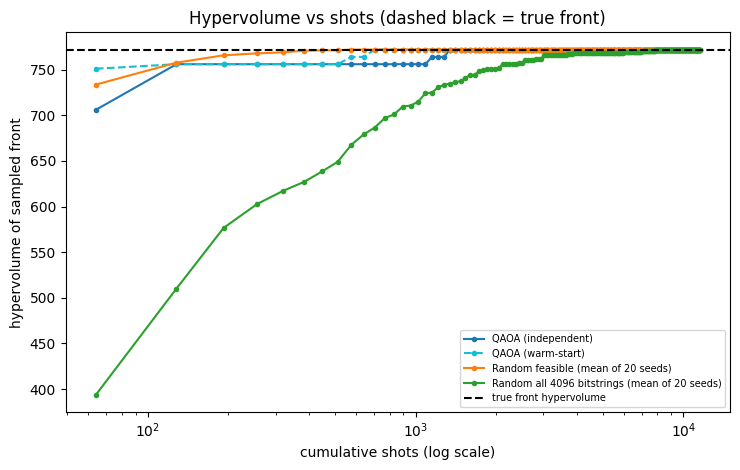

In [7]:
STYLE = {'QAOA (independent)': ('tab:blue', '-'), 'QAOA (warm-start)': ('tab:cyan', '--'),
         'Random feasible (mean of 20 seeds)': ('tab:orange', '-'),
         'Random all 4096 bitstrings (mean of 20 seeds)': ('tab:green', '-')}
for idx, (ylabel, title, fname) in enumerate([
        ('true Pareto points recovered (of 7)', 'Pareto points recovered vs shots', 'recovery_vs_shots.png'),
        ('hypervolume of sampled front', 'Hypervolume vs shots (dashed black = true front)', 'hypervolume_vs_shots.png')]):
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    for k, (col, ls) in STYLE.items():
        ax.plot(checkpoints, curves[k][idx], color=col, ls=ls, marker='o', ms=3, label=k)
    if idx == 0: ax.axhline(7, color='k', ls=':', label='all 7 front points')
    else: ax.axhline(hv_true, color='k', ls='--', label='true front hypervolume')
    ax.set_xscale('log'); ax.set_xlabel('cumulative shots (log scale)'); ax.set_ylabel(ylabel)
    ax.set_title(title); ax.legend(fontsize=7); fig.tight_layout()
    fig.savefig(f'{OUT}/{fname}', dpi=140); plt.show()

## 5. Which weighting found which front point?
For every true front point: the weightings whose 256 shots contained it (independent sweep) and the number of shots that hit it.

(6, 18, 6) found by 28/45 weightings | best weighting (cost,peak,wear)= (1.0, 0.0, 0.0) hits 142
(8, 14, 5) found by 42/45 weightings | best weighting (cost,peak,wear)= (0.875, 0.0, 0.125) hits 63
(10, 12, 6) found by 23/45 weightings | best weighting (cost,peak,wear)= (0.375, 0.625, 0.0) hits 12
(10, 14, 4) found by 42/45 weightings | best weighting (cost,peak,wear)= (0.625, 0.0, 0.375) hits 31
(11, 10, 4) found by 42/45 weightings | best weighting (cost,peak,wear)= (0.625, 0.25, 0.125) hits 52
(12, 18, 3) found by 35/45 weightings | best weighting (cost,peak,wear)= (0.0, 0.0, 1.0) hits 21
(13, 10, 3) found by 41/45 weightings | best weighting (cost,peak,wear)= (0.125, 0.0, 0.875) hits 46


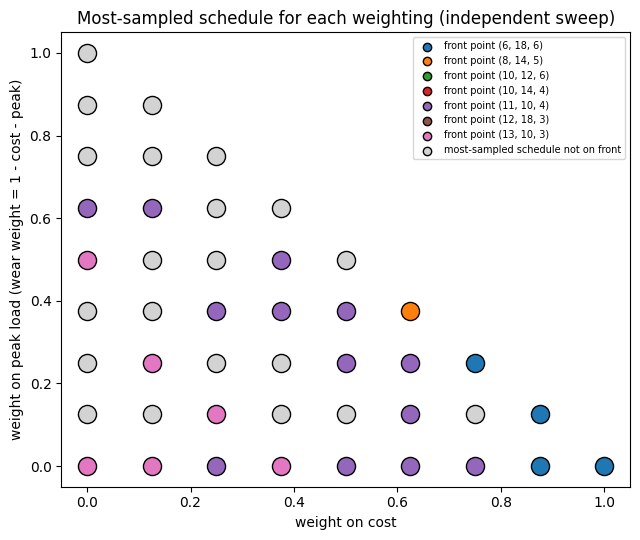

In [8]:
found_by = {p: [] for p in true_front}
for r in cold:
    for p in true_front:
        n = sum(1 for s in r['samples'] if s == p)
        if n: found_by[p].append((r['lam'], n))
for p, lst in found_by.items():
    best = max(lst, key=lambda t: t[1]) if lst else None
    print(p, f'found by {len(lst):2d}/{len(grid)} weightings', '| best weighting (cost,peak,wear)=',
          best[0] if best else None, 'hits', best[1] if best else 0)

# which front point (or other) is the most-sampled schedule for each weighting
def modal(r):
    from collections import Counter
    c = Counter(s for s in r['samples'] if s); return c.most_common(1)[0][0]
modes = [modal(r) for r in cold]
colour_of = {p: plt.cm.tab10(i) for i, p in enumerate(true_front)}
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for w, m in zip(grid, modes):
    on = m in colour_of
    ax.scatter(w[0], w[1], s=170, c=[colour_of[m]] if on else 'lightgrey', edgecolors='k')
for p in true_front:
    ax.scatter([], [], c=[colour_of[p]], edgecolors='k', label=f'front point {p}')
ax.scatter([], [], c='lightgrey', edgecolors='k', label='most-sampled schedule not on front')
ax.set_xlabel('weight on cost'); ax.set_ylabel('weight on peak load (wear weight = 1 - cost - peak)')
ax.set_title('Most-sampled schedule for each weighting (independent sweep)'); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{OUT}/weighting_map.png', dpi=140); plt.show()

In [9]:
# does the weighting *scalarisation* itself reach every front point? (exact optimum per weighting)
exact_hits = set()
for w in grid:
    sc = [sum(wi * v / s for wi, v, s in zip(w, t, scale)) for t in table]
    exact_hits.add(table[int(np.argmin(sc))])
exact_hits_front = [p for p in exact_hits if p in set(true_front)]
print('front points that are exact optima of some weighting:', len(exact_hits_front), 'of 7')

result = dict(grid=grid, shots_per_weighting=SHOTS_PER_WEIGHTING, p=P, true_front=true_front,
              reference_point=ref, hv_true=hv_true, checkpoints=checkpoints, summary=summary,
              feasible_fraction=feas_frac, runtime_s=dict(independent=t_cold, warm_start=t_warm),
              exact_scalarisation_front_points=len(exact_hits_front),
              mean_nfev=dict(independent=float(np.mean([r['nfev'] for r in cold])),
                             warm_start=float(np.mean([r['nfev'] for r in warm]))),
              mean_energy=dict(independent=float(np.mean([r['energy'] for r in cold])),
                               warm_start=float(np.mean([r['energy'] for r in warm]))),
              curves={k: dict(recovered=[float(x) for x in v[0]], hypervolume=[float(x) for x in v[1]])
                      for k, v in curves.items()},
              found_by={str(p): [dict(weights=l, hits=n) for l, n in lst] for p, lst in found_by.items()},
              random_final_front_spread=dict(feasible=[int(x) for x in rf_raw[0][-1]],
                                             all_bitstrings=[int(x) for x in ra_raw[0][-1]]),
              angles=[dict(lam=r['lam'], theta=r['theta'], energy=r['energy']) for r in cold])
with open(f'{OUT}/pareto_results.json', 'w') as f:
    json.dump(result, f, indent=1, default=float)
print('mean energy independent vs warm:', result['mean_energy'])

front points that are exact optima of some weighting: 5 of 7
mean energy independent vs warm: {'independent': 0.5398612635568344, 'warm_start': 0.5178180293664102}


In [10]:
# Shots needed to first see all 7 front points
def first_full(seq_, k=7):
    seen = set()
    for i, s in enumerate(seq_, 1):
        if s in set(true_front): seen.add(s)
        if len(seen) == k: return i
    return None
print('shots to recover all 7:  QAOA independent', first_full(seq['QAOA (independent)']),
      '| QAOA warm', first_full(seq['QAOA (warm-start)']),
      '| random feasible (per seed)', [first_full(r) for r in rand_feas][:10], '...')
print('QAOA shot order is weighting-by-weighting, so its count mixes early/late weightings.')

shots to recover all 7:  QAOA independent 1335 | QAOA warm 658 | random feasible (per seed) [437, 329, 302, 530, 196, 274, 541, 155, 314, 335] ...
QAOA shot order is weighting-by-weighting, so its count mixes early/late weightings.


## Findings & limitations

**What improved over the starting prototype.** One weighting gave one schedule. Sweeping 45 weightings (256 shots each, 11,520 shots total, p=2, XY mixer + Dicke start) recovered **all 7 of 7** true Pareto points in both QAOA variants, and the hypervolume of the sampled front equals the true front (772.0 of 772.0, reference point (22, 19, 10)). Every shot was feasible (100%), thanks to the constraint-preserving mixer. Even single weightings cover several front points: each front point was sampled by 23-42 of the 45 weightings, because the QAOA output distribution is broad, not a single peak. Extreme weightings found the extreme points most often (cost-only: (6,18,6); wear-only: (12,18,3) and (13,10,3)).

**Honest comparison with random sampling.** On this tiny instance (216 feasible schedules, 7 on the front) **uniform random sampling over feasible schedules does as well or better**: it also reaches 7/7 and full hypervolume at the same budget, and it got there faster (all 7 after roughly 150-540 shots depending on the seed, versus 1335 shots for independent QAOA and 658 for warm-started QAOA, whose shots are ordered weighting by weighting). At 256 shots QAOA had 5 points vs about 6.2 for random-feasible. QAOA clearly beats random sampling over **all 4096 bitstrings** (6.0/7 on average at 11,520 shots, 5% of shots feasible), but that baseline is a strawman because the Dicke start and XY mixer already enforce the constraints; the fair comparison is random-feasible. Part of QAOA's slower start is also that near-duplicate weightings resample the same few schedules.

**Parameter reuse.** Warm-starting from the previous weighting's angles gave slightly lower mean final energy (0.518 vs 0.540) and found all 7 points in fewer cumulative shots (658 vs 1335), but with one COBYLA restart and a 300-iteration cap both hit the cap on every weighting, so this is a small, single-seed effect, not a robust claim. The warm sweep also ran slower in wall-clock here only because the CPU was shared.

**Weighted sums are not enough.** Only 5 of the 7 front points are exact optima of some weighted-sum scalarisation on this grid (the other two are "unsupported" points inside the convex hull). QAOA still sampled them, since it returns a distribution rather than a single optimum - a genuine advantage of sampling over pure scalarisation, though random sampling finds them too.

**Limitations.** One small instance, one seed per weighting, 20 seeds for the random baseline; exact statevector simulation (no hardware noise); COBYLA capped at 300 iterations; sampling is multinomial from exact probabilities. A fair test of any QAOA advantage needs larger instances (more vehicles/slots) where random sampling cannot cover the feasible set, plus noise and fewer shots.
